# IEEE ACCESS — Graph-based Risk Quantification v5

**v5 변경사항 (vs v4):**
- CVSS: v2 only → **다중 버전 폴백 파이프라인** (v4.0/v3.1/v3.0/v2.0, NVD 우선)
- 데이터: `cwe.csv`+`cvss.csv` → NVD 공식 CSV
- V(s) 산출: 폴백 적용 후 max/10

In [4]:
# ============================================================
# CELL 0: CONFIG
# ============================================================
import os
from pathlib import Path

CSV_PATH   = r"D:\improveCIC-IDS-2018\combine\All_Combined_LIGHT.csv"
D3FEND_CSV = r"D:\improveCIC-IDS-2018\cvss\d3fend.csv"
OUT_DIR    = r"C:\Users\dshin\Desktop\LIG\Exp\out_v4"

# --- CVSS 다중 버전 폴백용 NVD 공식 CSV ---
CWE_CVSS_FILES = {
    'CWE-307': r"cwe307_cvss_scores_with_source.csv",
    'CWE-770': r"cwe770_cvss_scores.csv",
}

INTERNAL_PREFIX = "172.31."
TAU   = 3
ALPHA = 0.85
K_HOP = 3
N_WARMUP = 5
N_RUNS   = 50
MTTA_MANUAL_SEC = 300

TARGET_S1 = '172.31.69.25'
TARGET_S2 = '172.31.69.28'

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
for p, n in [(CSV_PATH,'CSV'),(D3FEND_CSV,'D3FEND')]:
    print(f"{n}: {'OK' if Path(p).exists() else 'NOT FOUND'} -> {p}")
for cwe, p in CWE_CVSS_FILES.items():
    print(f"{cwe}: {'OK' if Path(p).exists() else 'NOT FOUND'} -> {p}")

CSV: OK -> D:\improveCIC-IDS-2018\combine\All_Combined_LIGHT.csv
D3FEND: OK -> D:\improveCIC-IDS-2018\cvss\d3fend.csv
CWE-307: OK -> cwe307_cvss_scores_with_source.csv
CWE-770: OK -> cwe770_cvss_scores.csv


In [5]:
# ============================================================
# CELL 1: V(S) -- CVSS Multi-Version Fallback Pipeline
# ============================================================
# 기존 v4: cwe.csv + cvss.csv (CVSS v2 only)
# 변경 v5: NVD 공식 CSV (v2/v3.0/v3.1/v4.0 + NVD/CNA 소스 구분)
#
# 폴백 전략:
#   (1) NVD 점수 존재 -> NVD 내 최고 버전 (v3.1 > v3.0 > v2.0)
#   (2) NVD 부재      -> CNA 내 최고 버전 (v4.0 > v3.1)
#   (3) V(s) = max(선택된 점수) / 10
#
# 근거:
#   - NVD: NIST 단일 기관 일관 평가 -> 재현성 확보
#   - v4.0: 현재 NVD 미채점(100% CNA), v4.0 CNA vs v3.1 NVD 점수 역전 빈번
#     (CWE-770: 역전 37건 vs 정상 24건, 최대 5.2점 차이)
#   - CNA-only CVE 포함 -> 최신 위협(2024~2026 CVE) 커버
# ============================================================
import pandas as pd
import numpy as np

d3fend_df = pd.read_csv(D3FEND_CSV)

MAPPING_CHAIN = {
    'S1': {'attck': 'T1110.001', 'capec': 'CAPEC-49', 'cwe': 'CWE-307'},
    'S2': {'attck': 'T1498.001', 'capec': 'CAPEC-482', 'cwe': 'CWE-770'},
}

# --- 폴백 함수 ---
def select_best_cvss(cve_group):
    """단일 CVE: NVD 우선, 소스 내 최고 버전 선택"""
    nvd = cve_group[cve_group['source'].astype(str).str.startswith('nvd@')]
    cna = cve_group[~cve_group['source'].astype(str).str.startswith('nvd@')]
    if len(nvd) > 0:
        best = nvd.sort_values('version', ascending=False).iloc[0]
        return best['score'], best['version'], 'NVD'
    elif len(cna) > 0:
        best = cna.sort_values('version', ascending=False).iloc[0]
        return best['score'], best['version'], 'CNA'
    return None, None, None

# --- V(s) 산출 ---
V_SCORES = {}
table_ii_rows = []
pipeline_stats = {}

for sid, chain in MAPPING_CHAIN.items():
    cwe_id = chain['cwe']
    csv_path = CWE_CVSS_FILES[cwe_id]
    df = pd.read_csv(csv_path)
    
    # CVE별 최적 점수 선택
    results = []
    for cve_id_val, group in df.groupby('id'):
        score, version, src_type = select_best_cvss(group)
        if score is not None:
            results.append({
                'cve_id': cve_id_val, 'score': score,
                'version': version, 'source_type': src_type
            })
    
    res_df = pd.DataFrame(results)
    max_row = res_df.loc[res_df['score'].idxmax()]
    V = max_row['score'] / 10.0
    V_SCORES[sid] = V
    
    # 통계
    total = len(res_df)
    nvd31 = len(res_df[(res_df['source_type']=='NVD') & (res_df['version']==3.1)])
    nvd30 = len(res_df[(res_df['source_type']=='NVD') & (res_df['version']==3.0)])
    nvd20 = len(res_df[(res_df['source_type']=='NVD') & (res_df['version']==2.0)])
    cna_all = len(res_df[res_df['source_type']=='CNA'])
    cna_v4 = len(res_df[(res_df['source_type']=='CNA') & (res_df['version']==4.0)])
    
    pipeline_stats[sid] = {
        'total': total, 'nvd_v31': nvd31, 'nvd_v30': nvd30,
        'nvd_v20': nvd20, 'cna_all': cna_all, 'cna_v40': cna_v4,
    }
    
    print(f"")
    print(f"{'─'*60}")
    print(f"{sid}: {chain['attck']} -> {chain['capec']} -> {cwe_id}")
    print(f"  CVEs: {total} | NVD v3.1: {nvd31} | v3.0: {nvd30} | v2.0 fallback: {nvd20}")
    print(f"  CNA fallback: {cna_all} (incl. v4.0: {cna_v4})")
    print(f"  V(s) = {max_row['score']}/10 = {V:.4f}")
    print(f"    Max: {max_row['cve_id']} (CVSS v{max_row['version']} {max_row['source_type']})")
    
    for _, r in res_df.nlargest(5, 'score').iterrows():
        print(f"    {r['cve_id']:<20} {r['score']:>5.1f}  v{r['version']}  {r['source_type']}")
    
    table_ii_rows.append({
        'Scenario': sid, 'ATT&CK': chain['attck'],
        'CAPEC': chain['capec'], 'CWE': cwe_id,
        'CVE count': total, 'Representative CVE': max_row['cve_id'],
        'CVSS (ver)': f"{max_row['score']} (v{max_row['version']})",
        'V(S)': V,
    })

print("")
print("TABLE II: Threat-Vulnerability Mapping Chain")
display(pd.DataFrame(table_ii_rows))

# --- TABLE: CVSS Version Fallback Pipeline Statistics ---
pipe_rows = []
for sid in ['S1', 'S2']:
    ps = pipeline_stats[sid]
    pipe_rows.append({
        'Scenario': sid,
        'Total CVEs': ps['total'],
        'NVD v3.1': f"{ps['nvd_v31']} ({100*ps['nvd_v31']/ps['total']:.1f}%)",
        'NVD v3.0': f"{ps['nvd_v30']} ({100*ps['nvd_v30']/ps['total']:.1f}%)",
        'NVD v2.0 fallback': f"{ps['nvd_v20']} ({100*ps['nvd_v20']/ps['total']:.1f}%)",
        'CNA (NVD absent)': f"{ps['cna_all']} ({100*ps['cna_all']/ps['total']:.1f}%)",
        '  incl. v4.0': ps['cna_v40'],
    })
print("")
print("TABLE: CVSS Version Fallback Pipeline Statistics")
display(pd.DataFrame(pipe_rows))


────────────────────────────────────────────────────────────
S1: T1110.001 -> CAPEC-49 -> CWE-307
  CVEs: 306 | NVD v3.1: 272 | v3.0: 22 | v2.0 fallback: 0
  CNA fallback: 12 (incl. v4.0: 4)
  V(s) = 9.9/10 = 0.9900
    Max: CVE-2021-22530 (CVSS v3.1 NVD)
    CVE-2021-22530         9.9  v3.1  NVD
    CVE-1999-1324          9.8  v3.1  NVD
    CVE-2001-0395          9.8  v3.1  NVD
    CVE-2001-1291          9.8  v3.1  NVD
    CVE-2001-1339          9.8  v3.1  NVD

────────────────────────────────────────────────────────────
S2: T1498.001 -> CAPEC-482 -> CWE-770
  CVEs: 865 | NVD v3.1: 664 | v3.0: 92 | v2.0 fallback: 15
  CNA fallback: 94 (incl. v4.0: 24)
  V(s) = 9.9/10 = 0.9900
    Max: CVE-2023-43632 (CVSS v3.1 NVD)
    CVE-2023-43632         9.9  v3.1  NVD
    CVE-2017-6640          9.8  v3.0  NVD
    CVE-2017-6713          9.8  v3.0  NVD
    CVE-2018-20033         9.8  v3.1  NVD
    CVE-2019-17067         9.8  v3.1  NVD

TABLE II: Threat-Vulnerability Mapping Chain


,Scenario,ATT&CK,CAPEC,CWE,CVE count,Representative CVE,CVSS (ver),V(S)
0,S1,T1110.001,CAPEC-49,CWE-307,306,CVE-2021-22530,9.9 (v3.1),0.99
1,S2,T1498.001,CAPEC-482,CWE-770,865,CVE-2023-43632,9.9 (v3.1),0.99



TABLE: CVSS Version Fallback Pipeline Statistics


,Scenario,Total CVEs,NVD v3.1,NVD v3.0,NVD v2.0 fallback,CNA (NVD absent),incl. v4.0
0,S1,306,272 (88.9%),22 (7.2%),0 (0.0%),12 (3.9%),4
1,S2,865,664 (76.8%),92 (10.6%),15 (1.7%),94 (10.9%),24


In [6]:
# ============================================================

# CELL 1b: D3FEND 조회

# ============================================================

def lookup_d3fend(d3id):

    match = d3fend_df[d3fend_df['ID'] == d3id]

    if len(match) == 0: return None

    row = match.iloc[0]

    name = (row['D3FEND Technique'] if pd.notna(row['D3FEND Technique'])

            else row['D3FEND Technique Level 0'] if pd.notna(row['D3FEND Technique Level 0'])

            else row['D3FEND Technique Level 1'] if pd.notna(row['D3FEND Technique Level 1'])

            else '?')

    return {'id': d3id, 'tactic': row['D3FEND Tactic'], 'name': name}



for d3id in ['D3-MFA','D3-AL','D3-CH','D3-ITF',

             'D3-ISVA','D3-NTF','D3-BDI','D3-NI']:

    info = lookup_d3fend(d3id)

    print(f"  {'✓' if info else '✗'} {d3id:8s} | {info['tactic']:8s} | {info['name']}" if info else f"  ✗ {d3id}")

  ✓ D3-MFA   | Harden   | Multi-factor Authentication
  ✓ D3-AL    | Evict    | Account Locking
  ✓ D3-CH    | Harden   | Credential Hardening
  ✓ D3-ITF   | Isolate  | Inbound Traffic Filtering
  ✓ D3-ISVA  | Detect   | Inbound Session Volume Analysis
  ✓ D3-NTF   | Isolate  | Network Traffic Filtering
  ✓ D3-BDI   | Isolate  | Broadcast Domain Isolation
  ✓ D3-NI    | Isolate  | Network Isolation


In [7]:
# ============================================================

# CELL 2: 컬럼 탐지

# ============================================================

sample = pd.read_csv(CSV_PATH, nrows=5)

cols = sample.columns.tolist()

print("전체 컬럼:", cols)



src_col   = next(c for c in cols if 'src' in c.lower() and 'ip' in c.lower())

dst_col   = next(c for c in cols if 'dst' in c.lower() and 'ip' in c.lower())

label_col = next(c for c in cols if 'label' in c.lower())

print(f"src='{src_col}', dst='{dst_col}', label='{label_col}'")

display(sample[[src_col, dst_col, label_col]].head())

전체 컬럼: ['Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Label']
src='Src IP', dst='Dst IP', label='Label'


,Src IP,Dst IP,Label
0,172.31.66.5,72.21.91.29,BENIGN
1,172.31.66.5,54.192.16.165,BENIGN
2,172.31.66.5,52.179.17.38,BENIGN
3,172.31.66.5,13.89.187.212,BENIGN
4,172.31.66.5,65.55.44.108,BENIGN


In [8]:
# ============================================================

# CELL 3: 라벨 분포 + BENIGN 탐지

# ============================================================

CHUNK = 500_000

label_counts, total_rows = {}, 0

for chunk in pd.read_csv(CSV_PATH, usecols=[label_col], chunksize=CHUNK, low_memory=False):

    total_rows += len(chunk)

    for lbl, cnt in chunk[label_col].astype(str).str.strip().value_counts().items():

        label_counts[lbl] = label_counts.get(lbl, 0) + cnt



print(f"전체: {total_rows:,}\n")

for lbl, cnt in sorted(label_counts.items(), key=lambda x: -x[1]):

    print(f"  '{lbl}': {cnt:,}")



BENIGN_LABEL = next((l for l in label_counts if l.lower().strip()=='benign'), None)

print(f"\nBENIGN_LABEL = '{BENIGN_LABEL}'" if BENIGN_LABEL else "\n✗ 수동 설정 필요")

전체: 62,888,908

  'BENIGN': 59,353,486
  'DoS Hulk': 1,803,160
  'DDoS-HOIC': 1,082,293
  'DDoS-LOIC-HTTP': 289,328
  'Botnet Ares': 142,921
  'SSH-BruteForce': 94,197
  'Infiltration - NMAP Portscan': 89,374
  'DoS GoldenEye': 22,560
  'DoS Slowloris': 8,490
  'DDoS-LOIC-UDP': 2,527
  'Infiltration - Communication Victim Attacker': 204
  'Web Attack - Brute Force': 131
  'Web Attack - XSS': 113
  'Infiltration - Dropbox Download': 85
  'Web Attack - SQL': 39

BENIGN_LABEL = 'BENIGN'


In [9]:
# ============================================================

# CELL 4: 데이터 추출 (2가지 동시)

#   (A) 내부→내부 Benign  → 그래프 구축용 (I 산출)

#   (B) 전체→내부 Benign  → E(n) 산출용 (고유 유입 자산 수)

# ============================================================

assert BENIGN_LABEL

from collections import defaultdict



internal_chunks = []      # (A) 그래프용

inbound_src_sets = defaultdict(set)  # (B) E용: {dst_ip: {src1, src2, ...}}



for chunk in pd.read_csv(CSV_PATH, usecols=[src_col, dst_col, label_col],

                          chunksize=CHUNK, low_memory=False):

    chunk[label_col] = chunk[label_col].astype(str).str.strip()

    chunk[src_col]   = chunk[src_col].astype(str).str.strip()

    chunk[dst_col]   = chunk[dst_col].astype(str).str.strip()

    

    benign = chunk[chunk[label_col] == BENIGN_LABEL]

    

    # (A) 내부→내부

    int_int = benign[

        benign[src_col].str.startswith(INTERNAL_PREFIX) &

        benign[dst_col].str.startswith(INTERNAL_PREFIX)

    ][[src_col, dst_col]]

    if len(int_int) > 0:

        internal_chunks.append(int_int)

    

    # (B) 전체→내부 (내부+외부 모두 포함)

    int_dst = benign[benign[dst_col].str.startswith(INTERNAL_PREFIX)]

    for dst, src in zip(int_dst[dst_col], int_dst[src_col]):

        inbound_src_sets[dst].add(src)



if not internal_chunks:

    raise ValueError("내부-내부 Benign 0행 — IP 대역 확인")



internal_df = pd.concat(internal_chunks, ignore_index=True)



# E 원시값: 고유 유입 자산 수 (내부 src + 외부 src)

E_raw = {ip: len(srcs) for ip, srcs in inbound_src_sets.items()}



# 내부/외부 분리 통계

E_int_raw, E_ext_raw = {}, {}

for ip, srcs in inbound_src_sets.items():

    int_srcs = [s for s in srcs if s.startswith(INTERNAL_PREFIX)]

    ext_srcs = [s for s in srcs if not s.startswith(INTERNAL_PREFIX)]

    E_int_raw[ip] = len(int_srcs)

    E_ext_raw[ip] = len(ext_srcs)



print(f"✓ 내부-내부 Benign: {len(internal_df):,} rows")

print(f"✓ E(n) 수집: {len(E_raw)}개 내부 IP")

print(f"  고유 유입 자산 수 (내부+외부): min={min(E_raw.values())}, max={max(E_raw.values())}, "

      f"mean={np.mean(list(E_raw.values())):.1f}")



# 타겟 상세

for t, nm in [(TARGET_S1,'S1'), (TARGET_S2,'S2')]:

    total = E_raw.get(t, 0)

    i_cnt = E_int_raw.get(t, 0)

    e_cnt = E_ext_raw.get(t, 0)

    print(f"  {nm} ({t}): 고유유입={total} (내부={i_cnt}, 외부={e_cnt})")

✓ 내부-내부 Benign: 24,583,896 rows
✓ E(n) 수집: 464개 내부 IP
  고유 유입 자산 수 (내부+외부): min=18, max=6573, mean=2850.5
  S1 (172.31.69.25): 고유유입=4746 (내부=0, 외부=4746)
  S2 (172.31.69.28): 고유유입=3120 (내부=0, 외부=3120)


In [10]:
# 공격별 타겟 확인 + 시나리오 선정 근거

print("="*60)

print("시나리오 선정 근거")

print("="*60)

print("""

S1(SSH-BruteForce)과 S2(DDoS-HOIC)를 선정한 이유:

  1) 공격 메커니즘 대비: 인증 기반(Credential Access) vs 가용성 기반(Impact)

     → 서로 다른 ATT&CK Tactic, 다른 CWE, 다른 대응 유형

  2) 내부 확산 경로 명확: 두 공격 모두 특정 내부 타겟 IP가 식별 가능

  3) 대응 유형 다양성: V 감소형(MFA, 키인증) + E 감소형(ACL, 스크러빙)

     + I 감소형(CDN/LB) → 3축 모두 검증 가능

""")



for atk in ['SSH-BruteForce', 'DDoS-HOIC']:

    chunks = []

    for chunk in pd.read_csv(CSV_PATH, usecols=[src_col, dst_col, label_col],

                              chunksize=CHUNK, low_memory=False):

        chunk[label_col] = chunk[label_col].astype(str).str.strip()

        rows = chunk[chunk[label_col] == atk]

        if len(rows) > 0: chunks.append(rows)

    if chunks:

        df = pd.concat(chunks)

        print(f"\n{atk} ({len(df):,}):")

        print(df[dst_col].astype(str).str.strip().value_counts().head(5))

    else:

        print(f"\n{atk}: 없음 — 유사: {[l for l in label_counts if atk.split('-')[0].lower() in l.lower()]}")

시나리오 선정 근거


S1(SSH-BruteForce)과 S2(DDoS-HOIC)를 선정한 이유:

  1) 공격 메커니즘 대비: 인증 기반(Credential Access) vs 가용성 기반(Impact)

     → 서로 다른 ATT&CK Tactic, 다른 CWE, 다른 대응 유형

  2) 내부 확산 경로 명확: 두 공격 모두 특정 내부 타겟 IP가 식별 가능

  3) 대응 유형 다양성: V 감소형(MFA, 키인증) + E 감소형(ACL, 스크러빙)

     + I 감소형(CDN/LB) → 3축 모두 검증 가능



SSH-BruteForce (94,197):
Dst IP
172.31.69.25    94197
Name: count, dtype: int64

DDoS-HOIC (1,082,293):
Dst IP
172.31.69.28    1082293
Name: count, dtype: int64


In [11]:
internal_df.to_parquet(os.path.join(OUT_DIR, "step1_internal.parquet"), index=False)

print("저장 완료")

저장 완료


In [12]:
# ============================================================

# CELL 5: 그래프 구축  (두 타겟 동일 WCC 강제)

# ============================================================

import networkx as nx



edge_freq = internal_df.groupby([src_col, dst_col]).size().reset_index(name='freq')

print(f"고유 (src,dst): {len(edge_freq):,}")

print(f"빈도: min={edge_freq['freq'].min()}, max={edge_freq['freq'].max()}, "

      f"mean={edge_freq['freq'].mean():.1f}")



filtered = edge_freq[edge_freq['freq'] >= TAU]

print(f"τ={TAU} 후: {len(filtered):,} edges")



G = nx.DiGraph()

G.add_edges_from(zip(filtered[src_col], filtered[dst_col]))

print(f"초기: |N|={G.number_of_nodes()}, |E|={G.number_of_edges()}")



# --- 타겟 존재 확인 ---

for t, nm in [(TARGET_S1,'S1'), (TARGET_S2,'S2')]:

    if t in G:

        print(f"  ✓ {nm} ({t}): in={G.in_degree(t)}, out={G.out_degree(t)}")

    else:

        raise ValueError(f"타겟 {nm}({t})가 그래프에 없습니다. (TAU/IP필터 확인)")



# --- 두 타겟이 같은 약연결 컴포넌트인지 강제 ---

UG = G.to_undirected()

comp_s1 = nx.node_connected_component(UG, TARGET_S1)

comp_s2 = nx.node_connected_component(UG, TARGET_S2)



if comp_s1 != comp_s2:

    raise ValueError(

        "두 타겟이 서로 다른 약연결 컴포넌트에 있습니다.\n"

        "단일 그래프 비교 실험이 성립하지 않으므로, TAU/전처리/타겟을 재검토하세요."

    )



# --- 단일 기준 컴포넌트로 그래프 고정 ---

G = G.subgraph(comp_s1).copy()

UG = G.to_undirected()  # 이후 셀들이 UG를 쓰므로 갱신

print(f"최종(단일 WCC): |N|={G.number_of_nodes()}, |E|={G.number_of_edges()}")

고유 (src,dst): 1,552
빈도: min=1, max=84201, mean=15840.1
τ=3 후: 1,372 edges
초기: |N|=464, |E|=1372
  ✓ S1 (172.31.69.25): in=0, out=2
  ✓ S2 (172.31.69.28): in=0, out=2
최종(단일 WCC): |N|=464, |E|=1372


In [13]:
# TABLE IV

in_degs  = np.array([d for _, d in G.in_degree()])

out_degs = np.array([d for _, d in G.out_degree()])

display(pd.DataFrame({

    '지표': ['|N|','|E_G|','Avg in-deg','Max in-deg',

            'Avg out-deg','Max out-deg','Density','WCC'],

    '값': [G.number_of_nodes(), G.number_of_edges(),

          f"{in_degs.mean():.2f}", in_degs.max(),

          f"{out_degs.mean():.2f}", out_degs.max(),

          f"{nx.density(G):.4f}", 1]

}))

,지표,값
0,|N|,464
1,|E_G|,1372
2,Avg in-deg,2.96
3,Max in-deg,451
4,Avg out-deg,2.96
5,Max out-deg,91
6,Density,0.0064
7,WCC,1


In [14]:
# ============================================================

# CELL 6: I(n) = φ(PageRank) — 내부 구조 중심성

# ============================================================



def phi(values):

    """φ(x) = [log(1+x) - min] / [max - min] → [0,1]"""

    arr = np.asarray(values, dtype=float)

    log_v = np.log1p(arr)

    lo, hi = log_v.min(), log_v.max()

    return np.zeros_like(arr) if (hi - lo) < 1e-12 else (log_v - lo) / (hi - lo)



pr_raw = nx.pagerank(G, alpha=ALPHA)

nodes_list = list(G.nodes())

pr_arr = np.array([pr_raw[n] for n in nodes_list])

I_arr  = phi(pr_arr)



I_dict  = dict(zip(nodes_list, I_arr))

PR_dict = dict(zip(nodes_list, pr_arr))

nx.set_node_attributes(G, I_dict, 'I')



print(f"I(n): [{I_arr.min():.4f}, {I_arr.max():.4f}], mean={I_arr.mean():.4f}")

print("\nTop 10 I(n):")

for ip, v in sorted(I_dict.items(), key=lambda x: x[1], reverse=True)[:10]:

    print(f"  {ip}: I={v:.4f}")

I(n): [0.0000, 1.0000], mean=0.0083

Top 10 I(n):
  172.31.0.2: I=1.0000
  172.31.67.1: I=0.2495
  172.31.66.1: I=0.2495
  172.31.64.1: I=0.2388
  172.31.64.127: I=0.2364
  172.31.65.1: I=0.2289
  172.31.65.127: I=0.1956
  172.31.67.127: I=0.1876
  172.31.66.127: I=0.1708
  172.31.69.1: I=0.0526


In [15]:
# ============================================================

# CELL 7: ★ E(n) — φ(총 유입 유니크 통신원 수) (λ 제거)

# ============================================================

# Ein_raw: τ 필터된 내부 백본 그래프 G의 유니크 in-degree

# Eout_raw: Benign 외부→내부 유입의 유니크 외부 src 수 (τ 미적용)

# E_raw = Ein_raw + Eout_raw

# E(n) = φ(E_raw)  where φ = log1p + minmax



import numpy as np

import networkx as nx



# (1) 내부 유입원 수(유니크): 그래프 in-degree (τ 적용)

Ein_raw = dict(G.in_degree())  # 내부->내부, τ 반영



# (2) 외부 유입원 수(유니크): 외부->내부 benign에서 dst별 외부 src nunique (τ 미적용)

# E_ext_raw는 CELL 4에서 만든 dict: {dst_internal: unique_external_src_count}

Eout_raw = {n: E_ext_raw.get(n, 0) for n in nodes_list}



# (3) 총 유입 유니크 통신원 수

Eraw = {n: int(Ein_raw.get(n, 0)) + int(Eout_raw.get(n, 0)) for n in nodes_list}



# (4) 정규화 φ 적용

E_arr = phi(np.array([Eraw.get(n, 0) for n in nodes_list], dtype=float))

E_dict = dict(zip(nodes_list, E_arr))

nx.set_node_attributes(G, E_dict, 'E')



print(f"Ein_raw(τ적용 내부 유입원): min={min(Ein_raw.values())}, max={max(Ein_raw.values())}")

print(f"Eout_raw(외부 유입원): min={min(Eout_raw.values())}, max={max(Eout_raw.values())}")

print(f"Eraw(총 유입원): min={min(Eraw.values())}, max={max(Eraw.values())}")

print(f"E(n)=φ(Eraw): range=[{E_arr.min():.4f}, {E_arr.max():.4f}], mean={E_arr.mean():.4f}")



# Spearman(I, E)

from scipy.stats import spearmanr

I_arr = np.array([I_dict.get(n, 0) for n in nodes_list], dtype=float)

sp_r, _ = spearmanr(I_arr, E_arr)

print(f"Spearman ρ(I,E) = {sp_r:.4f}")

Ein_raw(τ적용 내부 유입원): min=0, max=451
Eout_raw(외부 유입원): min=0, max=6572
Eraw(총 유입원): min=9, max=6572
E(n)=φ(Eraw): range=[0.0000, 1.0000], mean=0.8442
Spearman ρ(I,E) = -0.1838


In [16]:
# ============================================================

# CELL 8: R(t,K) + Loss

# ============================================================



SCENARIOS = {

    'S1': {'name': 'SSH-BruteForce', 'target': TARGET_S1,

           'attck': 'T1110.001', 'capec': 'CAPEC-49', 'cwe': 'CWE-307',

           'V': V_SCORES['S1'], 'cvss': V_SCORES['S1']*10},

    'S2': {'name': 'DDoS-HOIC', 'target': TARGET_S2,

           'attck': 'T1498.001', 'capec': 'CAPEC-482', 'cwe': 'CWE-770',

           'V': V_SCORES['S2'], 'cvss': V_SCORES['S2']*10},

}



UG = G.to_undirected()

def get_R(target, K):

    if target not in UG: return set()

    return set(nx.single_source_shortest_path_length(UG, target, cutoff=K).keys())



rows_vi = []

for K_val in [1, 2, 3, 4]:

    row = {'K': K_val}

    for sid, s in SCENARIOS.items():

        sz = len(get_R(s['target'], K_val))

        row[f"{sid} |R|"] = sz

        row[f"{sid} %"] = f"{100*sz/G.number_of_nodes():.1f}%"

    rows_vi.append(row)

print("TABLE VI: |R(t,K)|")

display(pd.DataFrame(rows_vi))



loss_results = {}

for sid, s in SCENARIOS.items():

    R = get_R(s['target'], K_HOP)

    V = s['V']

    ie_sum = sum(I_dict.get(n,0) * E_dict.get(n,0) for n in R)

    loss   = V * ie_sum

    risks  = {n: I_dict.get(n,0) * E_dict.get(n,0) * V for n in R}

    loss_results[sid] = {'R': R, 'V': V, 'ie_sum': ie_sum, 'loss': loss,

                         'risks': risks, 'target': s['target']}

    print(f"\n{sid}: V={V}, |R(t,{K_HOP})|={len(R)}, Loss={loss:.6f}")

    for ip, r in sorted(risks.items(), key=lambda x: x[1], reverse=True)[:5]:

        print(f"  {ip}: Risk={r:.6f} (I={I_dict[ip]:.4f}, E={E_dict[ip]:.4f})")

TABLE VI: |R(t,K)|


,K,S1 |R|,S1 %,S2 |R|,S2 %
0,1,3,0.6%,3,0.6%
1,2,453,97.6%,453,97.6%
2,3,464,100.0%,464,100.0%
3,4,464,100.0%,464,100.0%



S1: V=0.99, |R(t,3)|=464, Loss=2.004521
  172.31.0.2: Risk=0.581520 (I=1.0000, E=0.5874)
  172.31.67.1: Risk=0.088033 (I=0.2495, E=0.3564)
  172.31.66.1: Risk=0.088032 (I=0.2495, E=0.3564)
  172.31.64.1: Risk=0.085684 (I=0.2388, E=0.3624)
  172.31.64.127: Risk=0.084487 (I=0.2364, E=0.3609)

S2: V=0.99, |R(t,3)|=464, Loss=2.004521
  172.31.0.2: Risk=0.581520 (I=1.0000, E=0.5874)
  172.31.67.1: Risk=0.088033 (I=0.2495, E=0.3564)
  172.31.66.1: Risk=0.088032 (I=0.2495, E=0.3564)
  172.31.64.1: Risk=0.085684 (I=0.2388, E=0.3624)
  172.31.64.127: Risk=0.084487 (I=0.2364, E=0.3609)


In [17]:
# ============================================================

# CELL 9: ★ 대응방안 정의 — D(c) 이진 평가 + 근거

# ============================================================

# D(c) = M + T + C  (인력, 기술, 비용 각 0/1)

#

# M(인력): 전문 보안 인력의 추가 투입이 필요한가?

#   0 = 기존 운영팀으로 설정 변경 가능

#   1 = 보안 전문가/컨설턴트 필요

#

# T(기술): 신규 소프트웨어·하드웨어 도입이 필요한가?

#   0 = 기존 인프라 설정 변경으로 충분

#   1 = 새로운 시스템/서비스 도입 필요

#

# C(비용): 추가 구매·라이선스·구독 비용이 발생하는가?

#   0 = 기존 예산 내 처리

#   1 = 추가 예산 편성 필요



CM_LOSS = {

    'S1': [

        {'name': 'MFA 적용',         'd3id': 'D3-MFA', 'affects': 'V',

         'tier': 'High', 'rr': 0.15,

         'M': 0, 'T': 1, 'C': 0,

         'D_reason': 'M=0: 기존 운영팀이 IdP 설정 가능; '

                     'T=1: MFA 앱/하드웨어 토큰 도입 필요 [Meyer 2023]; '

                     'C=0: 대부분의 IdP 무료 MFA 지원'},



        {'name': '계정 잠금 정책',    'd3id': 'D3-AL',  'affects': 'E',

         'tier': 'Medium', 'rr': 0.40,

         'M': 0, 'T': 0, 'C': 0,

         'D_reason': 'M=0: 기존 운영팀이 정책 변경; '

                     'T=0: OS/PAM 내장 기능; '

                     'C=0: 추가 비용 없음 [NIST SP 800-53 AC-7]'},



        {'name': 'SSH 키 인증 전환',  'd3id': 'D3-CH',  'affects': 'V',

         'tier': 'High', 'rr': 0.10,

         'M': 0, 'T': 1, 'C': 0,

         'D_reason': 'M=0: 기존 운영팀 SSH 설정; '

                     'T=1: 키 관리 체계(SSH CA/배포) 구축 필요; '

                     'C=0: OpenSSH 내장 [NIST SP 800-123]'},



        {'name': '네트워크 ACL',      'd3id': 'D3-ITF', 'affects': 'E',

         'tier': 'Medium', 'rr': 0.40,

         'M': 0, 'T': 1, 'C': 0,

         'D_reason': 'M=0: 기존 네트워크팀 운영; '

                     'T=1: 방화벽 룰 재설계·테스트 필요; '

                     'C=0: 기존 장비 활용 [NIST SP 800-53 SC-7]'},

    ],

    'S2': [

        {'name': 'Rate Limiting',     'd3id': 'D3-ISVA','affects': 'E',

         'tier': 'Medium', 'rr': 0.40,

         'M': 0, 'T': 0, 'C': 0,

         'D_reason': 'M=0: 기존 운영팀; '

                     'T=0: 웹서버/로드밸런서 내장 기능; '

                     'C=0: 추가 비용 없음 [Zargar 2013]'},



            # 기존

            # {'name': 'DDoS 스크러빙', 'd3id': 'D3-NTF', 'affects': 'E',

            #  'tier': 'High', 'rr': 0.10, 'M': 0, 'T': 1, 'C': 1},



        # 변경

        {'name': 'DDoS 스크러빙', 'd3id': 'D3-NTF', 'affects': 'E',

        'tier': 'High', 'rr': 0.10, 'M': 1, 'T': 1, 'C': 1,

        'D_reason': '임계값·정책 튜닝 및 오탐 관리에 DDoS 완화 전문 인력 필요; 스크러빙 서비스 도입 및 트래픽 기반 비용 발생'},



        {'name': 'CDN/로드밸런서',    'd3id': 'D3-BDI', 'affects': 'I',

         'tier': 'Medium', 'rr': 0.35,

         'M': 0, 'T': 1, 'C': 1,

         'D_reason': 'M=0: 기존 운영팀 구성 가능; '

                     'T=1: CDN 엣지/LB 인프라 도입; '

                     'C=1: CDN 서비스 구독 비용 [Zargar 2013]'},



        {'name': 'Blackhole Routing', 'd3id': 'D3-NI',  'affects': 'E',

         'tier': 'High', 'rr': 0.20,

         'M': 0, 'T': 1, 'C': 0,

         'D_reason': 'M=0: 기존 네트워크팀; '

                     'T=1: BGP 커뮤니티/라우팅 정책 구성; '

                     'C=0: ISP 기본 제공 [Zargar 2013]'},

    ],

}



for sid in CM_LOSS:

    for cm in CM_LOSS[sid]:

        cm['D'] = cm['M'] + cm['T'] + cm['C']



COUNTERMEASURES = CM_LOSS



# TABLE VII: D(c) 상세

vii_rows = []

for sid in ['S1','S2']:

    for cm in COUNTERMEASURES[sid]:

        info = lookup_d3fend(cm['d3id'])

        vii_rows.append({'S': sid, '대응방안': cm['name'], 'D3FEND': cm['d3id'],

                         'affects': cm['affects'], 'tier': cm['tier'], 'rr': cm['rr'],

                         'M': cm['M'], 'T': cm['T'], 'C': cm['C'], 'D': cm['D'],

                         '근거': cm['D_reason']})

print("TABLE VII: COUNTERMEASURES + D(c) 근거")

display(pd.DataFrame(vii_rows))

TABLE VII: COUNTERMEASURES + D(c) 근거


,S,대응방안,D3FEND,affects,tier,rr,M,T,C,D,근거
0,S1,MFA 적용,D3-MFA,V,High,0.15,0,1,0,1,M=0: 기존 운영팀이 IdP 설정 가능; T=1: MFA 앱/하드웨어 토큰 도입 ...
1,S1,계정 잠금 정책,D3-AL,E,Medium,0.40,0,0,0,0,M=0: 기존 운영팀이 정책 변경; T=0: OS/PAM 내장 기능; C=0: 추가...
2,S1,SSH 키 인증 전환,D3-CH,V,High,0.10,0,1,0,1,M=0: 기존 운영팀 SSH 설정; T=1: 키 관리 체계(SSH CA/배포) 구축...
3,S1,네트워크 ACL,D3-ITF,E,Medium,0.40,0,1,0,1,M=0: 기존 네트워크팀 운영; T=1: 방화벽 룰 재설계·테스트 필요; C=0: ...
4,S2,Rate Limiting,D3-ISVA,E,Medium,0.40,0,0,0,0,M=0: 기존 운영팀; T=0: 웹서버/로드밸런서 내장 기능; C=0: 추가 비용 ...
5,S2,DDoS 스크러빙,D3-NTF,E,High,0.10,1,1,1,3,임계값·정책 튜닝 및 오탐 관리에 DDoS 완화 전문 인력 필요; 스크러빙 서비스 ...
6,S2,CDN/로드밸런서,D3-BDI,I,Medium,0.35,0,1,1,2,M=0: 기존 운영팀 구성 가능; T=1: CDN 엣지/LB 인프라 도입; C=1:...
7,S2,Blackhole Routing,D3-NI,E,High,0.20,0,1,0,1,M=0: 기존 네트워크팀; T=1: BGP 커뮤니티/라우팅 정책 구성; C=0: I...


In [18]:
# ============================================================

# CELL 10: ΔLoss + Score

# ============================================================



def compute_loss_after(lr, cm):

    rr = float(cm['rr'])

    R, V, t = lr['R'], lr['V'], lr['target']

    ie_sum = lr['ie_sum']



    if cm['affects'] == 'V':

        return (V * rr) * ie_sum



    if cm['affects'] == 'I':

        it, et = I_dict.get(t, 0.0), E_dict.get(t, 0.0)

        ie_new = ie_sum - (it * et) + ((rr * it) * et)

        return V * ie_new



    if cm['affects'] == 'E':

        if t not in UG: return V * ie_sum

        N1 = set(nx.single_source_shortest_path_length(UG, t, cutoff=1).keys())

        S_e = R & N1

        sub = sum(I_dict.get(n,0) * E_dict.get(n,0) for n in S_e)

        ie_new = ie_sum - sub + rr * sub

        return V * ie_new



    raise ValueError(f"Unknown affects: {cm['affects']}")



cm_results = {}

for sid in ['S1', 'S2']:

    lr = loss_results[sid]

    L0 = lr['loss']

    rows = []

    for cm in COUNTERMEASURES[sid]:

        L1 = compute_loss_after(lr, cm)

        dL = L0 - L1

        rows.append({'대응방안': cm['name'], 'D3FEND': cm['d3id'],

                     'affects': cm['affects'], '등급': cm['tier'],

                     'rr': cm['rr'], 'D': cm['D'],

                     'Loss_after': L1, 'ΔLoss': dL,

                     'Score': dL / (cm['D'] + 1)})

    df = pd.DataFrame(rows)

    cm_results[sid] = df

    print(f"\n{'='*60}")

    print(f"{sid} (V={lr['V']}, |R|={len(lr['R'])}, Loss={L0:.6f})")

    display(df.sort_values('Score', ascending=False))


S1 (V=0.99, |R|=464, Loss=2.004521)


,대응방안,D3FEND,affects,등급,rr,D,Loss_after,ΔLoss,Score
2,SSH 키 인증 전환,D3-CH,V,High,0.10,1,0.200452,1.804068,0.902034
0,MFA 적용,D3-MFA,V,High,0.15,1,0.300678,1.703842,0.851921
1,계정 잠금 정책,D3-AL,E,Medium,0.40,0,1.650653,0.353868,0.353868
3,네트워크 ACL,D3-ITF,E,Medium,0.40,1,1.650653,0.353868,0.176934



S2 (V=0.99, |R|=464, Loss=2.004521)


,대응방안,D3FEND,affects,등급,rr,D,Loss_after,ΔLoss,Score
0,Rate Limiting,D3-ISVA,E,Medium,0.40,0,1.650653,0.353868,0.353868
3,Blackhole Routing,D3-NI,E,High,0.20,1,1.532697,0.471824,0.235912
1,DDoS 스크러빙,D3-NTF,E,High,0.10,3,1.473719,0.530801,0.132700
2,CDN/로드밸런서,D3-BDI,I,Medium,0.35,2,2.004521,0.000000,0.000000


In [19]:
# 민감도 분석

import itertools

from collections import Counter



TIER_RANGES = {

    'High':   [0.05, 0.10, 0.15, 0.20, 0.25],

    'Medium': [0.30, 0.35, 0.40, 0.45, 0.50],

}



sensitivity_results = {}

for sid in ['S1', 'S2']:

    lr, cms = loss_results[sid], COUNTERMEASURES[sid]

    L0 = lr['loss']

    combos = list(itertools.product(*[TIER_RANGES[cm['tier']] for cm in cms]))

    rank1_dl, rank1_sc = Counter(), Counter()

    for combo in combos:

        dls, scs = [], []

        for i, cm in enumerate(cms):

            L1 = compute_loss_after(lr, {**cm, 'rr': combo[i]})

            dl = L0 - L1

            dls.append(dl); scs.append(dl / (cm['D']+1))

        rank1_dl[cms[np.argmax(dls)]['name']] += 1

        rank1_sc[cms[np.argmax(scs)]['name']] += 1

    total = len(combos)

    sensitivity_results[sid] = {'total': total, 'rank1_dl': dict(rank1_dl), 'rank1_sc': dict(rank1_sc)}

    print(f"\n{sid} ({total} combos):")

    print(f"  ΔLoss: {' / '.join(f'{n} {100*c/total:.0f}%' for n,c in rank1_dl.most_common())}")

    print(f"  Score: {' / '.join(f'{n} {100*c/total:.0f}%' for n,c in rank1_sc.most_common())}")


S1 (625 combos):
  ΔLoss: MFA 적용 60% / SSH 키 인증 전환 40%
  Score: MFA 적용 60% / SSH 키 인증 전환 40%

S2 (625 combos):
  ΔLoss: DDoS 스크러빙 60% / Blackhole Routing 40%
  Score: Rate Limiting 100%


In [20]:
# ============================================================

# CELL 11: ★ MTTA — 전체 파이프라인 측정

# ============================================================

# 측정 범위: 그래프 구축 + I/E/V 산출 + Loss 재산출 + 최적 선정

#

# 실환경 시나리오:

#   공격 탐지됨 → 시스템이 현재 네트워크 상태를 반영한

#   그래프를 구축하고, I/E/V를 산출하고, 후보별 Loss를

#   재산출하여 최적 대응을 선정하기까지의 전체 시간

#

# 전체를 포함하는 이유:

#   그래프/I/E가 사전에 캐시되어 있다고 가정하면

#   측정이 비현실적으로 유리해지고, 리뷰어 방어 불가



import time



def run_full_pipeline(sid, internal_df_local, E_raw_local):

    """

    전체 파이프라인 1회 실행:

    (a) 그래프 구축

    (b) I(n) 산출 (PageRank + φ)

    (c) E(n) 산출 (고유 유입 자산 + φ)

    (d) V(S) 조회

    (e) R(t,K) + Loss 산출

    (f) 전체 후보 Loss_after + ΔLoss + Score

    (g) 최적 대응 선정

    """

    s = SCENARIOS[sid]

    

    # (a) 그래프 구축

    ef = internal_df_local.groupby([src_col, dst_col]).size().reset_index(name='freq')

    ef = ef[ef['freq'] >= TAU]

    g = nx.DiGraph()

    g.add_edges_from(zip(ef[src_col], ef[dst_col]))

    # WCC 필터 (타겟 포함 컴포넌트)

    for comp in nx.weakly_connected_components(g):

        if s['target'] in comp:

            g = g.subgraph(comp).copy()

            break

    

    # (b) I(n)

    pr = nx.pagerank(g, alpha=ALPHA)

    nlist = list(g.nodes())

    pr_a = np.array([pr[n] for n in nlist])

    i_a = phi(pr_a)

    i_d = dict(zip(nlist, i_a))

    

    # (c) E(n)

    e_raw_a = np.array([E_raw_local.get(n, 0) for n in nlist])

    e_a = phi(e_raw_a)

    e_d = dict(zip(nlist, e_a))

    

    # (d) V

    V = s['V']

    

    # (e) R + Loss

    ug = g.to_undirected()

    R = set(nx.single_source_shortest_path_length(ug, s['target'], cutoff=K_HOP).keys())

    ie_sum = sum(i_d.get(n,0) * e_d.get(n,0) for n in R)

    L0 = V * ie_sum

    

    # (f) 후보 평가

    cms = COUNTERMEASURES[sid]

    best_score = -1

    best_idx = 0

    lr_local = {'R': R, 'V': V, 'ie_sum': ie_sum, 'loss': L0, 'target': s['target']}

    

    for idx_cm, cm in enumerate(cms):

        rr = float(cm['rr'])

        t = s['target']

        

        if cm['affects'] == 'V':

            L1 = (V * rr) * ie_sum

        elif cm['affects'] == 'I':

            it, et = i_d.get(t, 0.0), e_d.get(t, 0.0)

            L1 = V * (ie_sum - it*et + rr*it*et)

        elif cm['affects'] == 'E':

            N1 = set(nx.single_source_shortest_path_length(ug, t, cutoff=1).keys())

            S_e = R & N1

            sub = sum(i_d.get(n,0) * e_d.get(n,0) for n in S_e)

            L1 = V * (ie_sum - sub + rr * sub)

        else:

            L1 = L0

        

        dL = L0 - L1

        sc = dL / (cm['D'] + 1)

        if sc > best_score:

            best_score = sc

            best_idx = idx_cm

    

    # (g) 선정

    return best_idx



# 실행

mtta_results = {}

for sid in ['S1', 'S2']:

    # 워밍업

    for _ in range(N_WARMUP):

        run_full_pipeline(sid, internal_df, E_raw)

    

    # 본 측정

    times = []

    for _ in range(N_RUNS):

        t0 = time.perf_counter()

        run_full_pipeline(sid, internal_df, E_raw)

        t1 = time.perf_counter()

        times.append(t1 - t0)

    

    times = np.array(times)

    med = np.median(times)

    imp = (MTTA_MANUAL_SEC - med) / MTTA_MANUAL_SEC * 100

    

    best = COUNTERMEASURES[sid][run_full_pipeline(sid, internal_df, E_raw)]['name']

    

    mtta_results[sid] = {

        'median_sec': med, 'median_ms': med*1000,

        'mean_ms': times.mean()*1000,

        'std_ms': times.std()*1000,

        'improvement': imp, 'times': times,

        'best_cm': best

    }

    

    print(f"\n{sid}: {SCENARIOS[sid]['name']}")

    print(f"  MTTA_auto  = {med*1000:.1f} ms ({med:.4f} sec)")

    print(f"  MTTA_manual = {MTTA_MANUAL_SEC} sec")

    print(f"  개선율 = {imp:.4f}%")

    print(f"  최적 대응: {best}")

    print(f"  범위: 그래프 구축 + I/E/V 산출 + Loss 재산출 + 최적 선정")


S1: SSH-BruteForce
  MTTA_auto  = 1634.0 ms (1.6340 sec)
  MTTA_manual = 300 sec
  개선율 = 99.4553%
  최적 대응: SSH 키 인증 전환
  범위: 그래프 구축 + I/E/V 산출 + Loss 재산출 + 최적 선정

S2: DDoS-HOIC
  MTTA_auto  = 1621.0 ms (1.6210 sec)
  MTTA_manual = 300 sec
  개선율 = 99.4597%
  최적 대응: Rate Limiting
  범위: 그래프 구축 + I/E/V 산출 + Loss 재산출 + 최적 선정


In [21]:
# ============================================================
# CELL 12: 최종 요약
# ============================================================
print("=" * 70)
print("FINAL SUMMARY v5")
print("=" * 70)
print(f"Graph: |N|={G.number_of_nodes()}, |E|={G.number_of_edges()}")
print(f"I(n) = phi(PageRank)")
print(f"E(n) = phi(unique inbound sources)")
print(f"Spearman rho(I,E) = {sp_r:.4f}")
print(f"V(s) = CVSS multi-version fallback (NVD first, CNA secondary)")
print(f"MTTA scope: full pipeline (graph -> I/E/V -> Loss -> selection)")

for sid in ['S1', 'S2']:
    s, lr, mr, df = SCENARIOS[sid], loss_results[sid], mtta_results[sid], cm_results[sid]
    se = sensitivity_results[sid]
    ps = pipeline_stats[sid]
    best_sc = max(se['rank1_sc'], key=se['rank1_sc'].get)
    print(f"")
    print(f"{sid}: {s['name']}")
    print(f"  V={s['V']:.4f} (CVSS fallback: NVD v3.1={ps['nvd_v31']}, v3.0={ps['nvd_v30']}, v2.0={ps['nvd_v20']}, CNA={ps['cna_all']})")
    print(f"  |R|={len(lr['R'])}, Loss={lr['loss']:.6f}")
    print(f"  dLoss 1st: {df.loc[df['ΔLoss'].idxmax(), '대응방안']}")
    print(f"  Score 1st: {df.loc[df['Score'].idxmax(), '대응방안']}")
    print(f"  Sensitivity: {best_sc} ({100*se['rank1_sc'][best_sc]/se['total']:.0f}%)")
    print(f"  MTTA: {mr['median_ms']:.1f} ms -> {mr['improvement']:.2f}% improvement")

FINAL SUMMARY v5
Graph: |N|=464, |E|=1372
I(n) = phi(PageRank)
E(n) = phi(unique inbound sources)
Spearman rho(I,E) = -0.1838
V(s) = CVSS multi-version fallback (NVD first, CNA secondary)
MTTA scope: full pipeline (graph -> I/E/V -> Loss -> selection)

S1: SSH-BruteForce
  V=0.9900 (CVSS fallback: NVD v3.1=272, v3.0=22, v2.0=0, CNA=12)
  |R|=464, Loss=2.004521
  dLoss 1st: SSH 키 인증 전환
  Score 1st: SSH 키 인증 전환
  Sensitivity: MFA 적용 (60%)
  MTTA: 1634.0 ms -> 99.46% improvement

S2: DDoS-HOIC
  V=0.9900 (CVSS fallback: NVD v3.1=664, v3.0=92, v2.0=15, CNA=94)
  |R|=464, Loss=2.004521
  dLoss 1st: DDoS 스크러빙
  Score 1st: Rate Limiting
  Sensitivity: Rate Limiting (100%)
  MTTA: 1621.0 ms -> 99.46% improvement


---

# 시각화

In [22]:
import matplotlib.pyplot as plt

import matplotlib

matplotlib.rcParams['font.family'] = 'Malgun Gothic'

matplotlib.rcParams['axes.unicode_minus'] = False

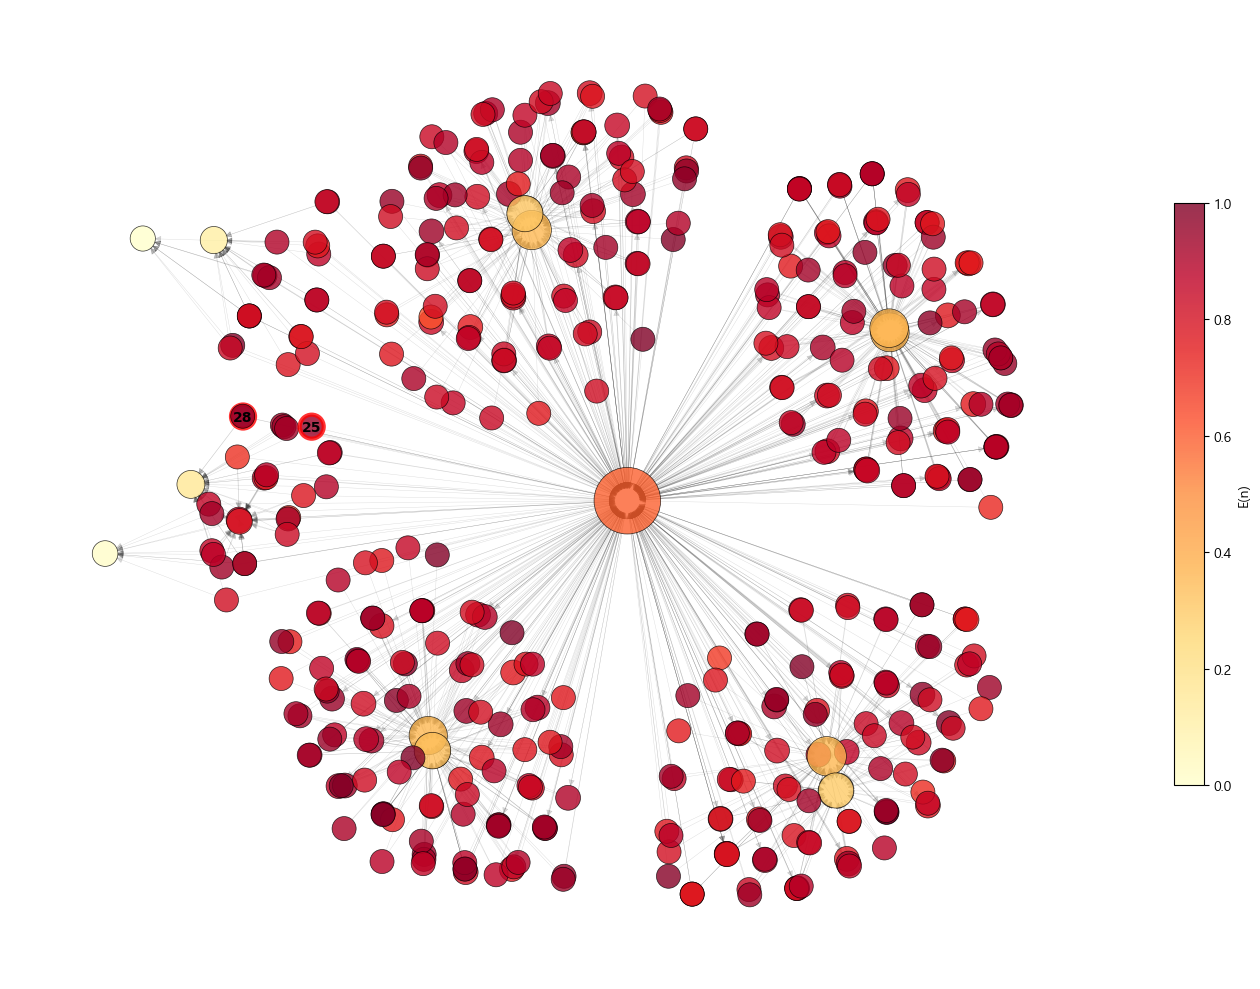

In [23]:
# FIG 2: 네트워크

fig, ax = plt.subplots(figsize=(14, 10))

np.random.seed(42)



# 레이아웃 계산

pos = nx.spring_layout(UG, seed=42, k=0.38/np.sqrt(G.number_of_nodes()), iterations=200)



# 노드 속성 설정

sizes  = [300 + 2000*I_dict.get(n,0) for n in G.nodes()]

colors = [E_dict.get(n,0) for n in G.nodes()]

ec = ['red' if n in {TARGET_S1, TARGET_S2} else 'none' for n in G.nodes()]

lw = [3 if n in {TARGET_S1, TARGET_S2} else 0.5 for n in G.nodes()]



# 그리기

nx.draw_networkx_edges(G, pos, alpha=0.15, width=0.3, ax=ax)

sc = nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=colors,

                            cmap=plt.cm.YlOrRd, edgecolors=ec, linewidths=lw, alpha=0.8, ax=ax)



# 특정 타겟 라벨링

nx.draw_networkx_labels(G, pos, {n: n.split('.')[-1] for n in {TARGET_S1, TARGET_S2} if n in G},

                        font_size=10, font_weight='bold', ax=ax)



# 컬러바 및 레이아웃 정리

plt.colorbar(sc, ax=ax, label='E(n)', shrink=0.6)



# --- 수정 부분: 제목 제거 및 축 오프 ---

ax.axis('off') 

plt.tight_layout()



# 저장 (bbox_inches='tight'는 여백 최소화에 필수입니다)

plt.savefig(os.path.join(OUT_DIR, 'fig2_network.png'), dpi=300, bbox_inches='tight')

plt.show()

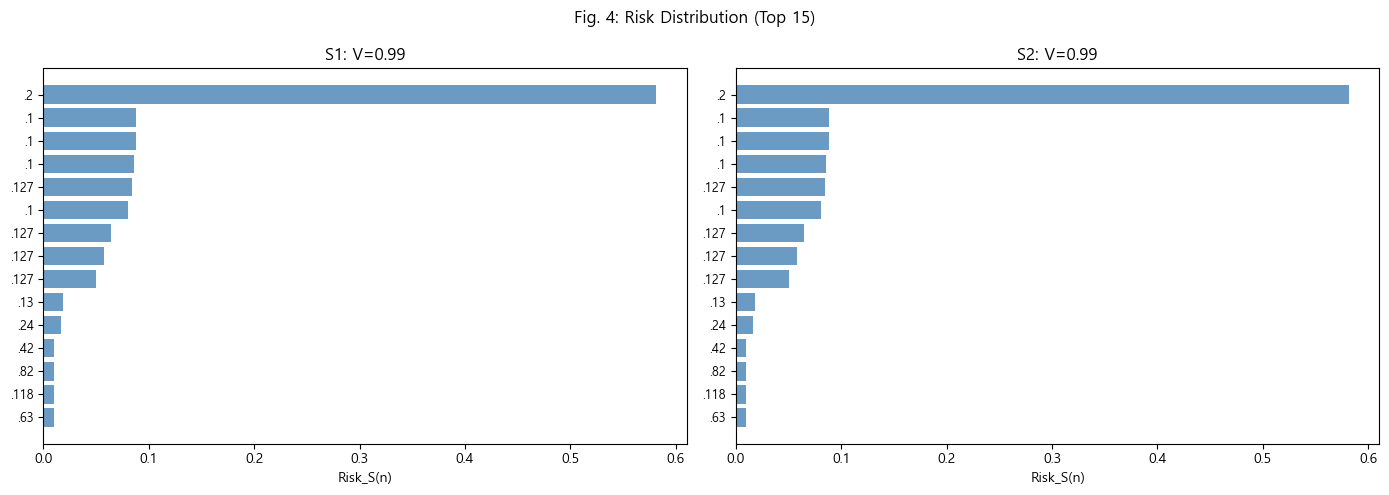

In [24]:
# FIG 4: Risk 분포

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, sid in enumerate(['S1', 'S2']):

    ax = axes[idx]

    sr = sorted(loss_results[sid]['risks'].items(), key=lambda x: x[1], reverse=True)[:15]

    names = [f".{ip.split('.')[-1]}" for ip, _ in sr]

    vals  = [v for _, v in sr]

    cols  = ['crimson' if ip == loss_results[sid]['target'] else 'steelblue' for ip, _ in sr]

    ax.barh(range(len(sr)), vals, color=cols, alpha=0.8)

    ax.set_yticks(range(len(sr))); ax.set_yticklabels(names, fontsize=9); ax.invert_yaxis()

    ax.set_xlabel('Risk_S(n)'); ax.set_title(f'{sid}: V={SCENARIOS[sid]["V"]}')

plt.suptitle('Fig. 4: Risk Distribution (Top 15)'); plt.tight_layout()

plt.savefig(os.path.join(OUT_DIR, 'fig4_risk.png'), dpi=300, bbox_inches='tight')

plt.show()

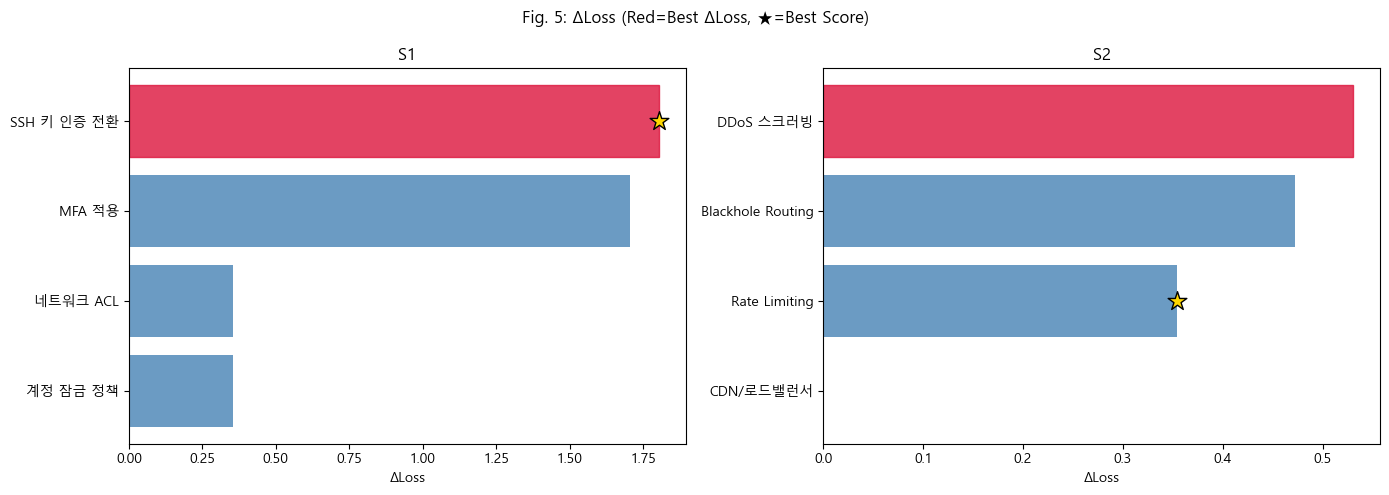

In [25]:
# FIG 5: ΔLoss

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, sid in enumerate(['S1', 'S2']):

    ax = axes[idx]

    df = cm_results[sid].sort_values('ΔLoss')

    bars = ax.barh(df['대응방안'], df['ΔLoss'], color='steelblue', alpha=0.8)

    best_i = df['ΔLoss'].idxmax()

    for bar, i in zip(bars, df.index):

        if i == best_i: bar.set_color('crimson')

    bs = df.loc[df['Score'].idxmax(), '대응방안']

    for j, n in enumerate(df['대응방안']):

        if n == bs:

            ax.scatter(df.iloc[j]['ΔLoss'], j, marker='*', s=200, c='gold', zorder=5, edgecolors='k')

    ax.set_xlabel('ΔLoss'); ax.set_title(f'{sid}')

plt.suptitle('Fig. 5: ΔLoss (Red=Best ΔLoss, ★=Best Score)'); plt.tight_layout()

plt.savefig(os.path.join(OUT_DIR, 'fig5_dloss.png'), dpi=300, bbox_inches='tight')

plt.show()

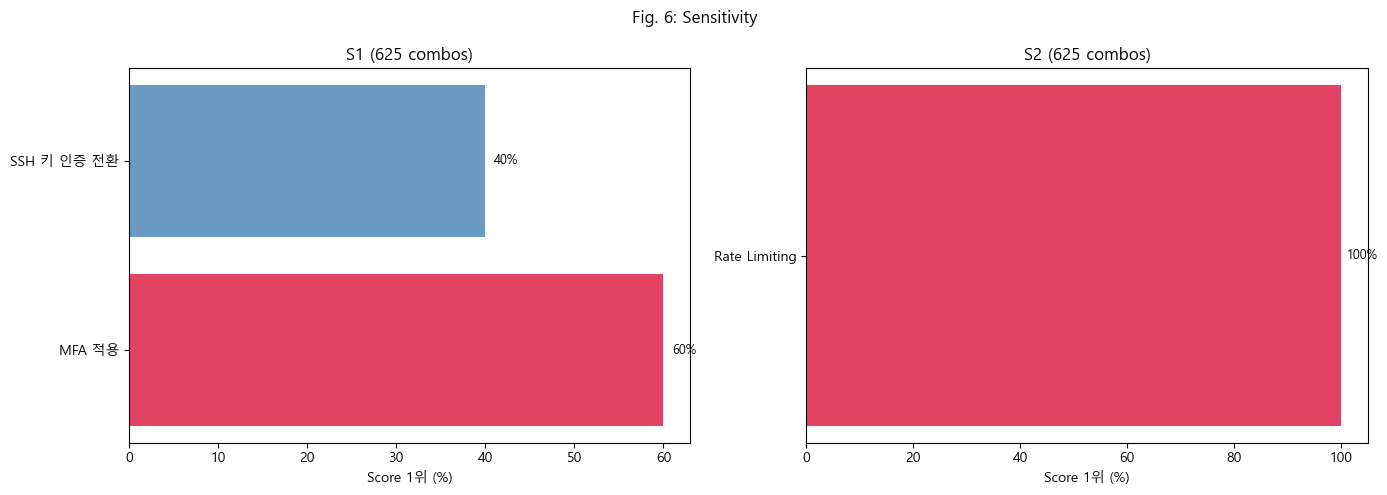

In [26]:
# FIG 6: 민감도

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, sid in enumerate(['S1', 'S2']):

    ax = axes[idx]; se = sensitivity_results[sid]

    names = list(se['rank1_sc'].keys()); pcts = [100*se['rank1_sc'][n]/se['total'] for n in names]

    cols = ['crimson' if p==max(pcts) else 'steelblue' for p in pcts]

    ax.barh(names, pcts, color=cols, alpha=0.8); ax.set_xlabel('Score 1위 (%)')

    ax.set_title(f'{sid} ({se["total"]} combos)')

    for i, p in enumerate(pcts): ax.text(p+1, i, f'{p:.0f}%', va='center', fontsize=9)

plt.suptitle('Fig. 6: Sensitivity'); plt.tight_layout()

plt.savefig(os.path.join(OUT_DIR, 'fig6_sensitivity.png'), dpi=300, bbox_inches='tight')

plt.show()

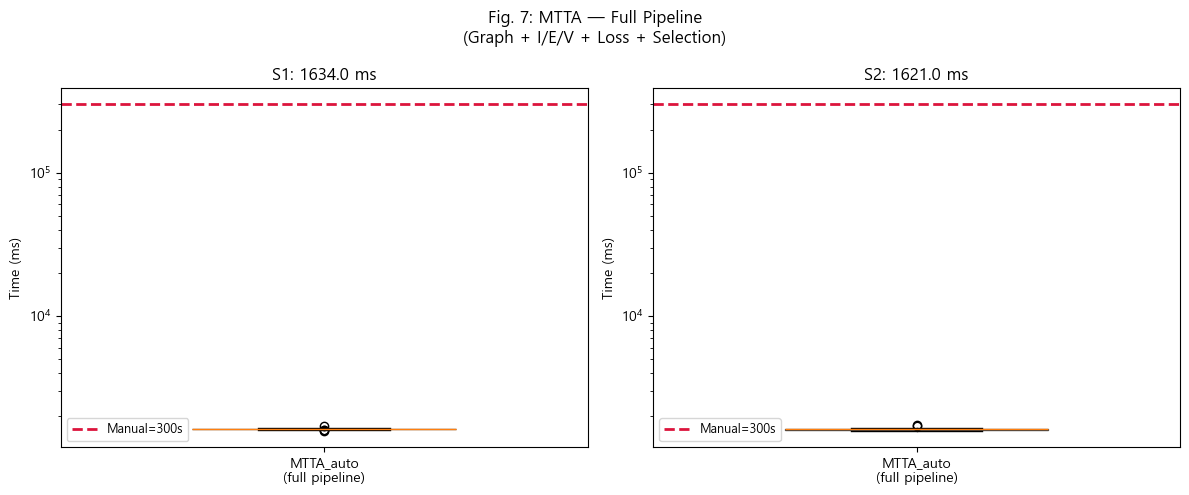

In [27]:
# FIG 7: MTTA (전체 파이프라인)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, sid in enumerate(['S1', 'S2']):

    ax = axes[idx]; mr = mtta_results[sid]

    ax.boxplot([mr['times']*1000], positions=[1], widths=0.5,

               patch_artist=True, boxprops=dict(facecolor='steelblue', alpha=0.7))

    ax.axhline(MTTA_MANUAL_SEC*1000, color='crimson', ls='--', lw=2,

               label=f'Manual={MTTA_MANUAL_SEC}s')

    ax.set_xticks([1]); ax.set_xticklabels(['MTTA_auto\n(full pipeline)'])

    ax.set_ylabel('Time (ms)'); ax.set_yscale('log')

    ax.set_title(f'{sid}: {mr["median_ms"]:.1f} ms')

    ax.legend(fontsize=9)

plt.suptitle('Fig. 7: MTTA — Full Pipeline\n(Graph + I/E/V + Loss + Selection)');

plt.tight_layout()

plt.savefig(os.path.join(OUT_DIR, 'fig7_mtta.png'), dpi=300, bbox_inches='tight')

plt.show()

In [28]:
# 결과 저장
import json as json_mod
nx.write_graphml(G, os.path.join(OUT_DIR, 'graph_final.graphml'))

pd.DataFrame([{'node_ip': n, 'I': I_dict[n], 'E': E_dict[n],
                'PR': PR_dict[n],
                'E_raw_total': E_raw.get(n, 0),
                'E_raw_int': E_int_raw.get(n, 0),
                'E_raw_ext': E_ext_raw.get(n, 0)}
               for n in nodes_list]
             ).to_csv(os.path.join(OUT_DIR, 'node_attributes.csv'), index=False)

for sid in ['S1','S2']:
    cm_results[sid].to_csv(os.path.join(OUT_DIR, f'cm_{sid}.csv'), index=False)

summary = {
    'version': 'v5',
    'E_formula': 'phi(unique_inbound_sources_int+ext)',
    'cvss': 'multi_version_fallback_nvd_first',
    'cvss_fallback': 'NVD(v3.1>v3.0>v2.0) then CNA(v4.0>v3.1)',
    'K_HOP': K_HOP,
    'mtta_scope': 'full_pipeline',
    'graph': {'N': G.number_of_nodes(), 'E': G.number_of_edges()},
    'pipeline_stats': pipeline_stats,
    'scenarios': {sid: {
        'V': SCENARIOS[sid]['V'],
        'R_size': len(loss_results[sid]['R']),
        'loss': loss_results[sid]['loss'],
        'mtta_ms': mtta_results[sid]['median_ms'],
        'best_cm': mtta_results[sid]['best_cm'],
    } for sid in ['S1','S2']}
}
with open(os.path.join(OUT_DIR, 'summary.json'), 'w') as f:
    json_mod.dump(summary, f, indent=2, default=str)
print(f"Saved to: {OUT_DIR}")

Saved to: C:\Users\dshin\Desktop\LIG\Exp\out_v4
